# Parte II — Experimentação

### Dependências

Instala as bibliotecas usadas no notebook. Execute esta célula se o ambiente ainda não estiver preparado.

In [ ]:
%pip install -r requirements.txt

# Imports e configurações

Reúne as bibliotecas e define o identificador da equipe, as sementes, as três taxas de aprendizado e os dois intervalos de pesos. Cada combinação será executada dez vezes.

In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

load_dotenv(Path(".env"))
TEAM_ID = 3
# Repetir as sementes permite reproduzir os experimentos.
BASE_SEED = 2026
REPETITIONS = 10
LEARNING_RATES = (0.4, 0.1, 0.01)
WEIGHT_INTERVALS = ((-100.0, 100.0), (-0.5, 0.5))


# Carregamento dos dados

Abre o arquivo binário NumPy da equipe 3, ajusta seu formato e verifica as entradas e os rótulos. Cada exemplo contém duas coordenadas e a classe desejada.

In [ ]:
print('Dados carregados para os experimentos:')
os.environ["DATASET_PATH_2"] = f".data/data{TEAM_ID}20262.txt"
DATASET_PATH = Path(os.getenv("DATASET_PATH_2"))
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f"Arquivo da equipe {TEAM_ID} não encontrado: {DATASET_PATH}")
data = np.load(DATASET_PATH, allow_pickle=False).squeeze()
if data.ndim != 2 or data.shape[1] != 3:
    raise ValueError("O dataset deve conter linhas (x1, x2, yd).")
if not np.isfinite(data).all() or not np.isin(data[:, -1], [0, 1]).all():
    raise ValueError("Dados inválidos: entradas finitas e classes 0/1 são necessárias.")
print(f"Arquivo: {DATASET_PATH} | Tipo: {type(data).__name__} | Dimensões: {data.shape}")
print("Primeiros cinco exemplos:\n", data[:5])
print("Contagem das classes:", dict(zip(*np.unique(data[:, -1].astype(int), return_counts=True))))

Dados carregados para os experimentos:
Arquivo: .data\data320262.txt | Tipo: ndarray | Dimensões: (1000, 3)
Primeiros cinco exemplos:
 [[ 146.2613139    56.98229034    1.        ]
 [ 527.3004796   623.38553402    1.        ]
 [  20.4577104   558.6793448     1.        ]
 [ 592.22660892  189.51000868    1.        ]
 [-182.84390621  342.55287961    1.        ]]
Contagem das classes: {np.int64(0): np.int64(346), np.int64(1): np.int64(654)}


# Visualização dos exemplos

Mostra os dados antes do treinamento: classe 0 em vermelho e classe 1 em azul.

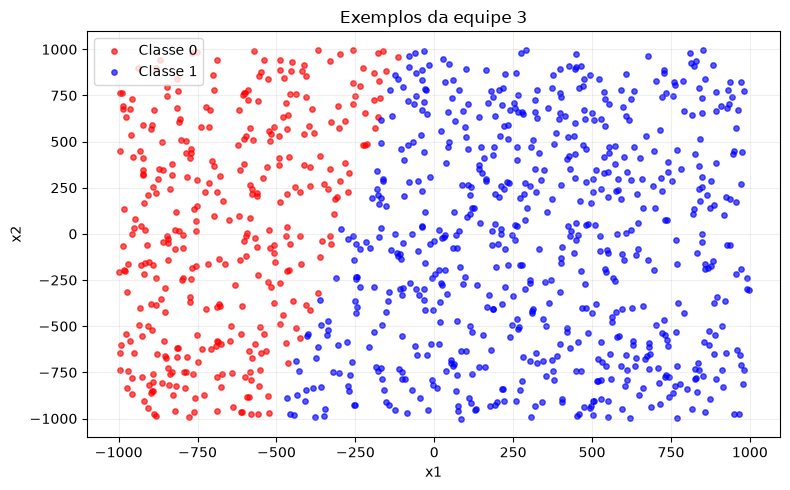

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, color in ((0, "red"), (1, "blue")):
    points = data[data[:, -1] == label]
    ax.scatter(points[:, 0], points[:, 1], color=color, label=f"Classe {label}", s=15, alpha=0.65)
ax.set(xlabel="x1", ylabel="x2", title=f"Exemplos da equipe {TEAM_ID}")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Neurônio da parte 1

A classe abaixo reproduz o código de `neuron.py`: bias na primeira entrada, pesos em NumPy, atualização pelo erro e parada após uma época sem ajustes. Os pesos começam em zero na classe e recebem a inicialização aleatória na célula dos experimentos.

Foram acrescentadas opções para dispensar o histórico de pesos e o gráfico individual nas 60 execuções. Essas opções não alteram o aprendizado. O gráfico também contempla a possibilidade de uma reta vertical.

In [ ]:
class Neuron:
    def __init__(self, dataset):
        self.dataset = dataset
        # A primeira entrada fica em 1 para representar o bias
        self.X = np.insert(dataset[:, :-1], 0, 1, axis=1)
        self.Yd = dataset[:, -1]
        self.weights = np.zeros(3, dtype=int)
        self.learning_rate = 0.1
        self.w_adjust_count = 0
        self.epochs = 0
        self.w_changes = np.empty((0, 3))
        self.record_history = True

    def threshold(self, inputs, weights):
        if len(inputs) != len(weights):
            raise ValueError("O vetor de entradas deve ter a mesma quantidade de elementos que o de pesos")
        v = 0.0
        for i in range(len(inputs)):
            v += inputs[i] * weights[i]
        if v < 0:
            return 0
        else:
            return 1

    def adjust_weights(self, inputs, weights, error):
        new_weights = []
        for wi, xi in zip(weights, inputs):
            new_weights.append(wi + self.learning_rate*error*xi)
        return new_weights

    def train(self, inputs, targets):
        print(f"Vetor inicial de pesos: {self.weights}")
        while True:
            had_error = False
            for xi, yi in zip(inputs, targets):
                output = self.threshold(xi, self.weights)
                error = yi - output
                if error != 0:
                    had_error = True
                    if self.record_history:
                        self.w_changes = np.vstack((self.w_changes, self.weights))
                    self.weights = self.adjust_weights(xi, self.weights, error)
                    self.w_adjust_count += 1
            self.epochs += 1
            # Se não há ajuste na época então há convergência
            if not had_error:
                break

    def execute(self, show_plot=True):
        self.train(self.X, self.Yd)
        print(f"Vetor final de pesos: {self.weights}")
        print(f"Número total de ajustes no vetor de pesos: {self.w_adjust_count}")
        print(f"Número de épocas até a convergência: {self.epochs}")
        if show_plot:
            self.plot()

    def plot(self):
        w0, w1, w2 = self.weights

        y0 = self.X[self.Yd == 0]
        y1 = self.X[self.Yd == 1]
        
        plt.scatter(y0[:, 1], y0[:, 2], color="red", label="Classe 0", s=20)
        plt.scatter(y1[:, 1], y1[:, 2], color="blue", label="Classe 1", s=20)

        x = np.array([self.X[:, 1].min(), self.X[:, 1].max()])
        if w2 != 0:
            y = -(w0 + w1 * x) / w2
            plt.plot(x, y, color="purple", label="Reta que separa as classes")
        elif w1 != 0:
            plt.axvline(-w0 / w1, color="purple", label="Reta que separa as classes")
        plt.xlabel("x1")
        plt.ylabel("x2")
        plt.legend()
        plt.show()

# Execução dos experimentos

Cria um neurônio novo a cada repetição, define a taxa e sorteia os três pesos no intervalo da configuração. A mesma semente é reutilizada entre configurações na repetição correspondente.

O histórico de pesos fica desativado para evitar copiar um array crescente a cada ajuste. Os gráficos individuais também ficam desativados; a comparação será apresentada nos boxplots. Cada execução só é registrada após convergir, com zero erros finais.

In [ ]:
print('Treinamento: seis configurações, com dez repetições cada.')
records = []
for learning_rate in LEARNING_RATES:
    for interval in WEIGHT_INTERVALS:
        config = f"η={learning_rate:g} | ({interval[0]:g}, {interval[1]:g})"
        for repetition in range(1, REPETITIONS + 1):
            print(f"\n{config} — repetição {repetition}/{REPETITIONS}")
            random.seed(BASE_SEED + repetition)
            neuron = Neuron(data)
            neuron.learning_rate = learning_rate
            neuron.weights = np.array([random.uniform(*interval) for _ in range(3)])
            neuron.record_history = False
            neuron.execute(show_plot=False)
            neuron.Yp = np.array([neuron.threshold(xi, neuron.weights) for xi in neuron.X])
            errors = int(np.count_nonzero(neuron.Yp != neuron.Yd))
            assert errors == 0, "A execução deve convergir antes de ser registrada."
            records.append({"configuracao": config, "taxa": learning_rate,
                            "intervalo": str(interval), "repeticao": repetition,
                            "semente": BASE_SEED + repetition, "ajustes": neuron.w_adjust_count,
                            "epocas": neuron.epochs, "erros_finais": errors,
                            "w1": neuron.weights[1], "w2": neuron.weights[2], "bias": neuron.weights[0]})
results = pd.DataFrame(records)
assert len(results) == 60
assert (results.groupby("configuracao").size() == REPETITIONS).all()
print(f"\nConcluídos: {len(results)} treinamentos; todos com zero erros finais.")

Treinamento: seis configurações, com dez repetições cada.

η=0.4 | (-100, 100) — repetição 1/10
Vetor inicial de pesos: [-78.33336454  -7.18959111 -97.28710554]
Vetor final de pesos: [ 5.72300666e+04  1.89658616e+02 -3.84799378e+01]
Número total de ajustes no vetor de pesos: 204511
Número de épocas até a convergência: 1531

η=0.4 | (-100, 100) — repetição 2/10
Vetor inicial de pesos: [-28.97842999 -64.24789323 -94.43953876]
Vetor final de pesos: [ 7.05622216e+04  2.34072354e+02 -4.79944588e+01]
Número total de ajustes no vetor de pesos: 263928
Número de épocas até a convergência: 2108

η=0.4 | (-100, 100) — repetição 3/10
Vetor inicial de pesos: [44.01837512 -3.23172063 84.76421412]
Vetor final de pesos: [ 6.02548184e+04  2.00719490e+02 -4.08423467e+01]
Número total de ajustes no vetor de pesos: 217533
Número de épocas até a convergência: 1654

η=0.4 | (-100, 100) — repetição 4/10
Vetor inicial de pesos: [-42.850993   -25.59631779   0.18109381]
Vetor final de pesos: [ 9.85115490e+04  3

# Tabela de resultados

Resume os dez treinamentos de cada configuração: média e desvio padrão amostral dos ajustes, além do menor e do maior número de épocas. A contagem inclui a época final sem ajustes.

In [ ]:
# O desvio padrão calculado por std é o amostral
summary = results.groupby("configuracao", sort=False).agg(
    taxa=("taxa", "first"), intervalo=("intervalo", "first"),
    media_ajustes=("ajustes", "mean"), desvio_ajustes=("ajustes", "std"),
    min_epocas=("epocas", "min"), max_epocas=("epocas", "max"),
    mediana_ajustes=("ajustes", "median")
).reset_index()
table = pd.DataFrame({
    "Taxa de aprendizado": summary.taxa,
    "Intervalo de pesos": summary.intervalo,
    "Qtde ajustes (média ± DP)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(summary.media_ajustes, summary.desvio_ajustes)],
    "Min épocas": summary.min_epocas,
    "Max épocas": summary.max_epocas,
})
print(table.to_string(index=False))

 Taxa de aprendizado Intervalo de pesos Qtde ajustes (média ± DP)  Min épocas  Max épocas
                0.40    (-100.0, 100.0)     290027.20 ± 105024.79        1531        5165
                0.40        (-0.5, 0.5)     268405.00 ± 111035.66         764        5065
                0.10    (-100.0, 100.0)      321405.90 ± 85513.83        1608        4462
                0.10        (-0.5, 0.5)      269486.40 ± 74027.97        1527        3686
                0.01    (-100.0, 100.0)      334057.10 ± 63778.46        1633        4621
                0.01        (-0.5, 0.5)     293375.20 ± 121309.53         759        5079


# Comparação com boxplots

Compara a distribuição dos ajustes e das épocas nas seis configurações. Os pontos representam as dez repetições; os triângulos indicam as médias.

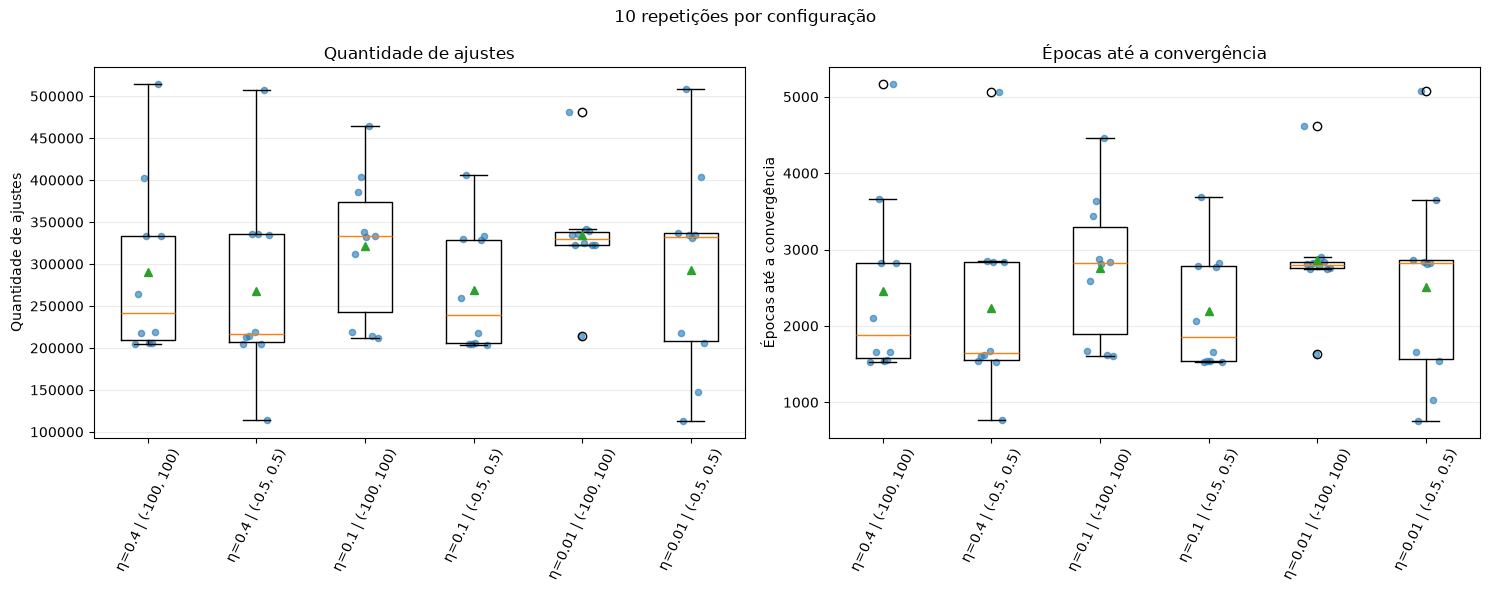

In [ ]:
labels = summary.configuracao.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric, title in zip(axes, ("ajustes", "epocas"), ("Quantidade de ajustes", "Épocas até a convergência")):
    groups = [results.loc[results.configuracao == label, metric].to_numpy() for label in labels]
    ax.boxplot(groups, tick_labels=labels, showmeans=True)
    # Cada ponto mostra uma das dez repetições
    for position, values in enumerate(groups, start=1):
        offsets = np.linspace(-0.12, 0.12, len(values))
        ax.scatter(position + offsets, values, s=20, alpha=0.6, color="tab:blue")
    ax.set(title=title, ylabel=title)
    ax.tick_params(axis="x", rotation=65)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("10 repetições por configuração")
plt.tight_layout()
plt.show()

# Análise dos resultados

Identifica as configurações com menor e maior média de ajustes e calcula a razão entre elas. A comparação descreve o custo de treinamento neste conjunto; não avalia generalização nem comprova equivalência estatística.

In [9]:
print('Comparação pelo número médio de ajustes:')
best = summary.loc[summary.media_ajustes.idxmin()]
worst = summary.loc[summary.media_ajustes.idxmax()]
print(f"Menor média de ajustes: {best.configuracao} ({best.media_ajustes:.2f} ± {best.desvio_ajustes:.2f}).")
print(f"Maior média de ajustes: {worst.configuracao} ({worst.media_ajustes:.2f} ± {worst.desvio_ajustes:.2f}).")
print(f"Razão entre a maior e a menor média: {worst.media_ajustes / best.media_ajustes:.2f}.")
print("Todas as execuções convergiram com zero erros nos dados de treinamento.")
print("A menor média indica menor custo neste experimento; a sobreposição dos boxplots não comprova equivalência.")


Comparação pelo número médio de ajustes:
Menor média de ajustes: η=0.4 | (-0.5, 0.5) (268405.00 ± 111035.66).
Maior média de ajustes: η=0.01 | (-100, 100) (334057.10 ± 63778.46).
Razão entre a maior e a menor média: 1.24.
Todas as execuções convergiram com zero erros nos dados de treinamento.
A menor média indica menor custo neste experimento; a sobreposição dos boxplots não comprova equivalência.
